# Tangent stiffness matrix and its product by a vector: verification and cost

The geometrically non-linear analyses of `panels` need the internal force vector $\boldsymbol{F}_{int}(\boldsymbol{c})$
of [`Shell.calc_fint`](../shell.rst), the tangent stiffness matrix $\boldsymbol{K}_T = \partial
\boldsymbol{F}_{int}/\partial \boldsymbol{c}$ of [`Shell.calc_kT`](../shell.rst), and, for the prescribed
displacements imposed exactly, the product $\boldsymbol{K}_T \boldsymbol{v}$ of
[`Shell.calc_kTv`](../shell.rst), computed without assembling $\boldsymbol{K}_T$. The theory is in
[Tangent stiffness matrix and its product by a vector](../tangent_product.rst) and the structure of the kernels in
[Approximation functions tabulated at the integration points](../tabulation.rst).

This notebook

1. rebuilds, for the classical laminated plate theory with the Donnell kinematics, the operators
   $\boldsymbol{B}_L$, $\boldsymbol{B}_{NL}$ and $\boldsymbol{G}$ from the Bardell functions, and compares the
   matrices and the vector of the equations with those of the compiled kernels;
2. checks that $\boldsymbol{K}_T$ and $\boldsymbol{K}_T \boldsymbol{v}$ are the derivative of
   $\boldsymbol{F}_{int}$ with a Taylor test, for all the non-linear models;
3. measures the cost of the assembly, of the internal force vector and of the product, and the run time of a
   displacement-controlled post-buckling analysis.

All times are measured on the machine that executed this notebook (for the stored outputs: one core of a node of the
hpc12 cluster), with one thread.

In [1]:
%matplotlib inline
import os
import sys
import time

import numpy as np
import matplotlib.pyplot as plt
from numpy.polynomial.legendre import leggauss
from IPython.display import Markdown, display
from structsolve import Analysis

import panels.bardell as bardell
from panels import modelDB
from panels.shell import Shell
from panels.multidomain import MultiDomain

sys.path.insert(0, os.path.join('..', 'tests', 'tests_shell'))
sys.path.insert(0, os.path.join('..', 'tests', 'multidomain'))
from test_tangent_consistency import MODELS, make_shell, random_state
from test_null_space_pd import plate_postbuckling


def table(headers, rows):
    lines = ['| ' + ' | '.join(headers) + ' |', '|' + '---|'*len(headers)]
    lines += ['| ' + ' | '.join(str(v) for v in row) + ' |' for row in rows]
    display(Markdown('\n'.join(lines)))


def rel(A, B):
    A = A.toarray() if hasattr(A, 'toarray') else np.asarray(A)
    B = B.toarray() if hasattr(B, 'toarray') else np.asarray(B)
    return np.abs(A - B).max()/np.abs(B).max()


def median_time(func, repeat):
    func()  # warm-up
    times = []
    for _ in range(repeat):
        t0 = time.perf_counter()
        func()
        times.append(time.perf_counter() - t0)
    return np.median(times)

## 1. The operators of the Donnell kinematics, rebuilt

With the Bardell functions $P_i$ and the natural coordinates $\xi = 2x/a - 1$, $\eta = 2y/b - 1$, the displacements are
$u = \boldsymbol{S}^u \boldsymbol{c}$, $v = \boldsymbol{S}^v \boldsymbol{c}$, $w = \boldsymbol{S}^w \boldsymbol{c}$,
with $S^u_{3(jm+i)} = P_i^u(\xi) P_j^u(\eta)$, $S^v_{3(jm+i)+1}$ and $S^w_{3(jm+i)+2}$ alike, each function with the
boundary flags of its displacement component (`calc_vec_f`, `calc_vec_fp`, `calc_vec_fpp` of `panels.bardell`). The
strains of the Donnell kinematics, the plate being the limit $1/r = 0$, are

$$\hat{\boldsymbol{\varepsilon}} = \left(\boldsymbol{B}_L + \tfrac{1}{2} \boldsymbol{B}_{NL}\right) \boldsymbol{c},\quad
\boldsymbol{B}_L = \begin{bmatrix} \boldsymbol{S}^u_{,x} \\ \boldsymbol{S}^v_{,y} + \boldsymbol{S}^w/r \\
\boldsymbol{S}^u_{,y} + \boldsymbol{S}^v_{,x} \\ -\boldsymbol{S}^w_{,xx} \\ -\boldsymbol{S}^w_{,yy} \\
-2\boldsymbol{S}^w_{,xy} \end{bmatrix},\quad
\boldsymbol{G} = \begin{bmatrix} \boldsymbol{S}^w_{,x} \\ \boldsymbol{S}^w_{,y} \end{bmatrix},\quad
\boldsymbol{B}_{NL} = \begin{bmatrix} w_{,x} \boldsymbol{G}_1 \\ w_{,y} \boldsymbol{G}_2 \\ w_{,y} \boldsymbol{G}_1 +
w_{,x} \boldsymbol{G}_2 \\ \boldsymbol{0} \end{bmatrix}$$

and, with the laminate stiffness $\boldsymbol{C}$ and $\tilde{\boldsymbol{N}}$ the $2 \times 2$ matrix of the membrane
forces,

$$\boldsymbol{F}_{int} = \int (\boldsymbol{B}_L + \boldsymbol{B}_{NL})^\top \boldsymbol{C} \hat{\boldsymbol{\varepsilon}}
\, dA, \qquad \boldsymbol{K}_T = \int (\boldsymbol{B}_L + \boldsymbol{B}_{NL})^\top \boldsymbol{C} (\boldsymbol{B}_L +
\boldsymbol{B}_{NL}) \, dA + \int \boldsymbol{G}^\top \tilde{\boldsymbol{N}} \boldsymbol{G} \, dA .$$

`calc_kC(c, NLgeom=True)` (kernel `fkC_num`) returns the first integral plus the geometric stiffness of the non-linear
membrane forces $\boldsymbol{N}_{NL} = \boldsymbol{A} \{w_{,x}^2/2,\ w_{,y}^2/2,\ w_{,x} w_{,y}\}$, and `calc_kG(c)`
(kernel `fkG_num`) the geometric stiffness of the linear membrane forces $\boldsymbol{N}_L$, so that their sum is
$\boldsymbol{K}_T$. Below, the integrals are evaluated in Python with $10 \times 10$ Gauss-Legendre points, for
$m = n = 4$ terms, an unsymmetric laminate $[30/-45/0/90]$ (so that $\boldsymbol{B} \ne \boldsymbol{0}$ and $A_{16},
A_{26} \ne 0$) and a random state with deflections of about twenty thicknesses, and compared with the kernels. The
closed-form kernels of the linear matrices, `fk0` and `fkG0`, are compared with the numerical ones at $\boldsymbol{c} =
\boldsymbol{0}$, integrated exactly with $30 \times 30$ points.

In [2]:
def operators(s, xi, eta):
    r'''S^u, S^v, S^w and their derivatives in x, y at one point, rows of size 3 m n'''
    m, n = s.m, s.n
    size = 3*m*n
    out = {}
    for k, f in enumerate('uvw'):
        fx = [np.asarray(g(xi, *(getattr(s, 'x1' + f), getattr(s, 'x1' + f + 'r'),
                                  getattr(s, 'x2' + f), getattr(s, 'x2' + f + 'r'))))[:m]
              for g in (bardell.calc_vec_f, bardell.calc_vec_fp, bardell.calc_vec_fpp)]
        gy = [np.asarray(g(eta, *(getattr(s, 'y1' + f), getattr(s, 'y1' + f + 'r'),
                                   getattr(s, 'y2' + f), getattr(s, 'y2' + f + 'r'))))[:n]
              for g in (bardell.calc_vec_f, bardell.calc_vec_fp, bardell.calc_vec_fpp)]
        for name, dx, dy, scale in (('', 0, 0, 1.), ('x', 1, 0, 2/s.a), ('y', 0, 1, 2/s.b),
                                    ('xx', 2, 0, 4/s.a**2), ('yy', 0, 2, 4/s.b**2), ('xy', 1, 1, 4/(s.a*s.b))):
            row = np.zeros(size)
            # column 3 (j m + i) + k
            row[k::3] = scale*np.outer(gy[dy], fx[dx]).ravel()
            out[f + name] = row
    return out


def rebuilt(s, c, nx=10, ny=10):
    size = s.get_size()
    C = np.asarray(s.ABD)
    A = C[:3, :3]
    invr = 0. if s.r is None else 1./s.r
    KC = np.zeros((size, size))
    KG = np.zeros((size, size))
    fint = np.zeros(size)
    px, wx = leggauss(nx)
    py, wy = leggauss(ny)
    for xi, wi in zip(px, wx):
        for eta, wj in zip(py, wy):
            S = operators(s, xi, eta)
            BL = np.array([S['ux'], S['vy'] + invr*S['w'], S['uy'] + S['vx'],
                           -S['wxx'], -S['wyy'], -2*S['wxy']])
            G = np.array([S['wx'], S['wy']])
            wxc, wyc = G @ c
            BNL = np.zeros_like(BL)
            BNL[0] = wxc*G[0]
            BNL[1] = wyc*G[1]
            BNL[2] = wyc*G[0] + wxc*G[1]
            weight = wi*wj*s.a*s.b/4
            eps = (BL + 0.5*BNL) @ c
            sigma = C @ eps
            NL = (C @ (BL @ c))[:3]
            NNL = A @ np.array([wxc**2/2, wyc**2/2, wxc*wyc])
            Ntil = lambda N: np.array([[N[0], N[2]], [N[2], N[1]]])
            B = BL + BNL
            KC += weight*(B.T @ C @ B + G.T @ Ntil(NNL) @ G)
            KG += weight*(G.T @ Ntil(NL) @ G)
            fint += weight*(B.T @ sigma)
    return KC, KG, fint


rows = []
for model in ('plate_clpt_donnell', 'cylshell_clpt_donnell'):
    s = make_shell(model)
    s.m = s.n = 4
    s._rebuild()
    c = random_state(s, np.random.default_rng(1))
    KC, KG, fint = rebuilt(s, c)
    r = [rel(s.calc_kC(c=c, NLgeom=True, nx=10, ny=10), KC),
         rel(s.calc_kG(c=c, nx=10, ny=10), KG),
         rel(s.calc_fint(c, nx=10, ny=10), fint)]
    zero = np.zeros(s.get_size())
    r.append(rel(s.calc_kC(c=zero, nx=30, ny=30), s.calc_kC()))
    s.Nxx, s.Nyy, s.Nxy = -1.e3, -0.5e3, 0.2e3
    r.append(rel(s.calc_kG(c=zero, nx=30, ny=30), s.calc_kG()))
    rows.append(r)
names = [('`fkC_num`', 'first integral + $\\boldsymbol{K}_G(\\boldsymbol{N}_{NL})$'),
         ('`fkG_num`', '$\\boldsymbol{K}_G(\\boldsymbol{N}_L)$'),
         ('`calc_fint`', '$\\boldsymbol{F}_{int}$'),
         ('`fk0`', '`fkC_num` at $\\boldsymbol{c} = \\boldsymbol{0}$, $30 \\times 30$ points'),
         ('`fkG0`', '`fkG_num` at $\\boldsymbol{c} = \\boldsymbol{0}$, constant $N_{xx}, N_{yy}, N_{xy}$, '
                    '$30 \\times 30$ points')]
table(['kernel', 'compared with', 'plate', 'cylinder'],
      [[k, e, '%.1e' % rows[0][i], '%.1e' % rows[1][i]] for i, (k, e) in enumerate(names)])

| kernel | compared with | plate | cylinder |
|---|---|---|---|
| `fkC_num` | first integral + $\boldsymbol{K}_G(\boldsymbol{N}_{NL})$ | 8.8e-16 | 1.1e-15 |
| `fkG_num` | $\boldsymbol{K}_G(\boldsymbol{N}_L)$ | 2.1e-15 | 1.8e-15 |
| `calc_fint` | $\boldsymbol{F}_{int}$ | 1.2e-15 | 1.7e-15 |
| `fk0` | `fkC_num` at $\boldsymbol{c} = \boldsymbol{0}$, $30 \times 30$ points | 5.3e-15 | 5.1e-15 |
| `fkG0` | `fkG_num` at $\boldsymbol{c} = \boldsymbol{0}$, constant $N_{xx}, N_{yy}, N_{xy}$, $30 \times 30$ points | 1.0e-14 | 1.0e-14 |

The relative differences, largest entry of the difference over the largest entry, are at the round-off level: the
kernels compute the equations above, and the closed-form and the numerically integrated linear matrices agree once the
quadrature integrates the polynomials exactly.

## 2. Consistency: Taylor tests

For an arbitrary state $\boldsymbol{c}$ and direction $\boldsymbol{v}$,
$\boldsymbol{F}_{int}(\boldsymbol{c} + h\boldsymbol{v}) = \boldsymbol{F}_{int}(\boldsymbol{c}) + h
\boldsymbol{K}_T(\boldsymbol{c}) \boldsymbol{v} + O(h^2)$, so the relative remainder

$$e(h) = \frac{\| \boldsymbol{F}_{int}(\boldsymbol{c} + h\boldsymbol{v}) - \boldsymbol{F}_{int}(\boldsymbol{c}) - h
\boldsymbol{K}_T \boldsymbol{v} \|}{\| h \boldsymbol{K}_T \boldsymbol{v} \|}$$

falls proportionally to $h$ when $\boldsymbol{K}_T$ is the Jacobian, and stalls otherwise. The test is done for every
geometrically non-linear model with the product `calc_kTv`, and the product is compared with `calc_kT(c) @ v`. The
shells are those of the test module `test_tangent_consistency.py`: $0.3 \times 0.2$ m, $r = 0.4$ m for the cylinders,
$[30/-45/0/90]$, $5 \times 5$ terms, $8 \times 8$ points.

| model | `calc_kTv` vs `calc_kT @ v` | $e(0.01)$ | $e(0.001)$ | $e(0.0001)$ | $e(1e-05)$ | $e(1e-06)$ | spread of $e/h$ |
|---|---|---|---|---|---|---|---|
| `plate_clpt_donnell` | 6.7e-16 | 1.6e-04 | 1.6e-05 | 1.6e-06 | 1.6e-07 | 1.6e-08 | 1.01 |
| `cylshell_clpt_donnell` | 7.7e-16 | 2.5e-04 | 2.5e-05 | 2.5e-06 | 2.5e-07 | 2.5e-08 | 1.01 |
| `cylshell_clpt_sanders` | 1.9e-15 | 2.5e-04 | 2.5e-05 | 2.5e-06 | 2.5e-07 | 2.5e-08 | 1.02 |
| `plate_fsdt_donnell` | 2.3e-16 | 1.0e-04 | 1.0e-05 | 1.0e-06 | 1.0e-07 | 1.1e-08 | 1.02 |
| `plate_tsdt_donnell` | 7.9e-16 | 1.0e-04 | 1.0e-05 | 1.0e-06 | 1.0e-07 | 1.0e-08 | 1.01 |
| `cylshell_fsdt_donnell` | 2.5e-16 | 1.4e-04 | 1.4e-05 | 1.4e-06 | 1.4e-07 | 1.4e-08 | 1.00 |
| `cylshell_fsdt_sanders` | 9.9e-16 | 1.3e-04 | 1.3e-05 | 1.3e-06 | 1.3e-07 | 1.3e-08 | 1.01 |
| `cylshell_tsdt_donnell` | 3.3e-16 | 1.4e-04 | 1.4e-05 | 1.4e-06 | 1.4e-07 | 1.4e-08 | 1.01 |
| `cylshell_tsdt_sanders` | 2.5e-16 | 1.3e-04 | 1.3e-05 | 1.3e-06 | 1.3e-07 | 1.3e-08 | 1.01 |
| `plate_clpt_gl` | 2.7e-16 | 2.1e-04 | 2.1e-05 | 2.1e-06 | 2.1e-07 | 2.1e-08 | 1.03 |
| `plate_clpt_tl` | 5.4e-16 | 2.1e-04 | 2.1e-05 | 2.1e-06 | 2.1e-07 | 2.1e-08 | 1.02 |

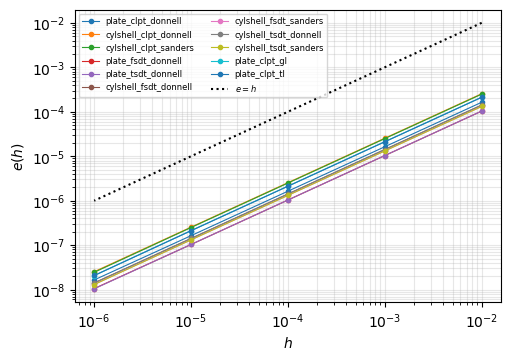

In [3]:
steps = [1e-2, 1e-3, 1e-4, 1e-5, 1e-6]
rows = []
taylor = {}
for model in MODELS:
    s = make_shell(model)
    rng = np.random.default_rng(0)
    c = random_state(s, rng)
    v = random_state(s, rng)
    f0 = s.calc_fint(c)
    kTv = s.calc_kTv(c, v)
    e = [np.linalg.norm(s.calc_fint(c + h*v) - f0 - h*kTv)/np.linalg.norm(h*kTv) for h in steps]
    taylor[model] = e
    rows.append(['`%s`' % model, '%.1e' % rel(kTv, s.calc_kT(c=c) @ v)] + ['%.1e' % x for x in e]
                + ['%.2f' % (max(x/h for x, h in zip(e, steps))/min(x/h for x, h in zip(e, steps)))])
table(['model', '`calc_kTv` vs `calc_kT @ v`'] + ['$e(%g)$' % h for h in steps] + ['spread of $e/h$'], rows)

fig, ax = plt.subplots(figsize=(5.5, 3.8))
for model, e in taylor.items():
    ax.loglog(steps, e, '.-', lw=0.8, label=model)
ax.loglog(steps, steps, 'k:', label='$e = h$')
ax.set_xlabel('$h$')
ax.set_ylabel('$e(h)$')
ax.grid(alpha=0.3, which='both')
ax.legend(fontsize=6, ncol=2)
plt.show()

The remainder falls by ten per decade of $h$ for every model, $e(h)/h$ being nearly constant, and the product equals
the assembled matrix times the vector to round-off.

## 3. Cost of the assembly and of the product

Single shell, $0.3 \times 0.2$ m, $r = 0.4$ m for the cylinder, laminate $[0/45/-45/90]$, the default integration
points of `panels.shell.gauss_points`, $\max(2m - 1, 7)$ by $\max(2n - 1, 7)$, the random state of section 2. Medians
of 5 samples after a warm-up (3 for `calc_kT`); ratio: `calc_kT` over `calc_kTv`. The assembly of $\boldsymbol{K}_T$
loops over the $m^2 n^2$ pairs of terms at each integration point, the internal force vector and the product over the
$m n$ terms, so that the ratio grows with the number of terms.

In [4]:
def perf_shell(model, m):
    s = make_shell(model)
    s.stack = [0, 45, -45, 90]
    s.m = s.n = m
    s.nx = s.ny = None
    s._rebuild()
    return s


perf = {}
rows = []
for model in ('plate_clpt_donnell', 'cylshell_fsdt_sanders', 'plate_tsdt_donnell'):
    for m in (8, 12, 16):
        s = perf_shell(model, m)
        rng = np.random.default_rng(0)
        c = random_state(s, rng)
        v = random_state(s, rng)
        tkT = median_time(lambda: s.calc_kT(c=c), 3)
        tf = median_time(lambda: s.calc_fint(c), 5)
        tv = median_time(lambda: s.calc_kTv(c, v), 5)
        d = rel(s.calc_kTv(c, v), s.calc_kT(c=c) @ v)
        perf[(model, m)] = (tkT, tf, tv)
        rows.append(['`%s`' % model, m, s.get_size(), '%d x %d' % (s.nx, s.ny), '%.3g s' % tkT, '%.3g ms' % (1e3*tf),
                     '%.3g ms' % (1e3*tv), '%.0f' % (tkT/tv), '%.2f' % (tv/tf), '%.1e' % d])
table(['model', '$m = n$', 'size', 'points', '`calc_kT`', '`calc_fint`', '`calc_kTv`', 'ratio',
       '`calc_kTv`/`calc_fint`', 'difference'], rows)

| model | $m = n$ | size | points | `calc_kT` | `calc_fint` | `calc_kTv` | ratio | `calc_kTv`/`calc_fint` | difference |
|---|---|---|---|---|---|---|---|---|---|
| `plate_clpt_donnell` | 8 | 192 | 15 x 15 | 0.053 s | 2.59 ms | 2.92 ms | 18 | 1.13 | 2.9e-16 |
| `plate_clpt_donnell` | 12 | 432 | 23 x 23 | 0.588 s | 14 ms | 16 ms | 37 | 1.14 | 6.9e-16 |
| `plate_clpt_donnell` | 16 | 768 | 31 x 31 | 3.27 s | 48.7 ms | 54.6 ms | 60 | 1.12 | 7.0e-16 |
| `cylshell_fsdt_sanders` | 8 | 320 | 15 x 15 | 0.221 s | 4.18 ms | 4.62 ms | 48 | 1.11 | 5.9e-16 |
| `cylshell_fsdt_sanders` | 12 | 720 | 23 x 23 | 2.43 s | 23.2 ms | 25 ms | 97 | 1.08 | 6.3e-16 |
| `cylshell_fsdt_sanders` | 16 | 1280 | 31 x 31 | 13.7 s | 80.8 ms | 85.1 ms | 161 | 1.05 | 5.3e-16 |
| `plate_tsdt_donnell` | 8 | 320 | 15 x 15 | 0.317 s | 4.45 ms | 4.89 ms | 65 | 1.10 | 1.0e-15 |
| `plate_tsdt_donnell` | 12 | 720 | 23 x 23 | 3.62 s | 24.3 ms | 26.6 ms | 136 | 1.09 | 7.6e-16 |
| `plate_tsdt_donnell` | 16 | 1280 | 31 x 31 | 20.5 s | 83.9 ms | 91.2 ms | 224 | 1.09 | 1.1e-15 |

### Kernels of the other matrices

The same shells, $m = n = 12$, with a follower pressure of $-2 \times 10^4$ Pa: run times of the non-linear
constitutive matrix (`calc_kC(c, NLgeom=True)`, kernel `fkC_num`), the geometric stiffness matrix (`calc_kG(c)`,
`fkG_num`), the internal force vector, the load stiffness of the follower pressure (`calc_kCfollower`,
`fkCfollower_num`) and the mass matrix integrated numerically with a thickness per integration point (`calc_kM` with
`h_nxny`, `fkM_num`). Each kernel evaluates the approximation functions once per integration point and term, in a table
read by the loops over the terms.

In [5]:
rows = []
for model in ('plate_clpt_donnell', 'cylshell_fsdt_sanders', 'plate_tsdt_donnell'):
    s = perf_shell(model, 12)
    s.rho = 1600.
    s.add_pressure_load(-2.e4, follower='linear')
    c = random_state(s, np.random.default_rng(0))
    h_nxny = np.full((s.nx, s.ny), s.lam.h)
    times = [median_time(lambda: s.calc_kC(c=c, NLgeom=True), 3),
             median_time(lambda: s.calc_kG(c=c), 3),
             median_time(lambda: s.calc_fint(c), 5),
             median_time(lambda: s.calc_kCfollower(c=c), 3),
             median_time(lambda: s.calc_kM(h_nxny=h_nxny), 3)]
    rows.append(['`%s`' % model] + ['%.3g s' % t for t in times])
table(['model, $m = n = 12$', '`fkC_num`', '`fkG_num`', '`calc_fint`', '`fkCfollower_num`', '`fkM_num`'], rows)

| model, $m = n = 12$ | `fkC_num` | `fkG_num` | `calc_fint` | `fkCfollower_num` | `fkM_num` |
|---|---|---|---|---|---|
| `plate_clpt_donnell` | 0.786 s | 0.0567 s | 0.0264 s | 0.251 s | 0.133 s |
| `cylshell_fsdt_sanders` | 2.72 s | 0.124 s | 0.0356 s | 0.409 s | 0.135 s |
| `plate_tsdt_donnell` | 3.79 s | 0.0648 s | 0.0368 s | 0.255 s | 0.714 s |

## 4. Displacement-controlled post-buckling

The simply supported isotropic plate of the test module `test_null_space_pd.py` ($a = 0.3$ m, $b = 0.2$ m, $h = 1$ mm,
$E = 70$ GPa), $m = n = 12$ terms, under an end-shortening of three times the critical one of its linear buckling
analysis, imposed exactly with the null-space method, with a lateral point load of 2 N as imperfection. The reduced
problem of [`MultiDomain.get_reduced_functions`](../multidomain.rst) needs, at each assembly of the tangent stiffness
matrix, $\partial \boldsymbol{R}_r/\partial \lambda = -\boldsymbol{Z}^\top (\boldsymbol{F}_{ext} - \boldsymbol{K}_T
\boldsymbol{c}_{p1})$, computed with the product. Run time of `Analysis.static`, median of 3 runs, with the
Newton-Raphson method, the modified Newton-Raphson method (`modified_NR = True`) and Riks's arc-length method, with
Crisfield's convergence criterion (the default, `relTOL = 1e-9`) and with the relative one (`relTOL = 1e-6`), and the
number of assemblies of $\boldsymbol{K}_T$ and the axial reaction at $\lambda = 1$.

In [6]:
import functools


def postbuckling(method, criterion, relTOL):
    md, p, delta = plate_postbuckling(m=12, n=12)
    fext, fint, kC, kG = md.get_reduced_functions()
    n = {'kC': 0}

    @functools.wraps(kC)
    def ckC(*args, **kwargs):
        n['kC'] += 1
        return kC(*args, **kwargs)

    an = Analysis(fext, fint, ckC, kG)
    an.convergence = criterion
    an.relTOL = relTOL
    if method == 'modified NR':
        an.modified_NR = True
    elif method == 'Riks':
        an.NL_method = 'arc_length_riks'
        an.initialInc = 0.2
        an.maxArcLength = 100.
    t0 = time.perf_counter()
    an.static(NLgeom=True, silent=True)
    t = time.perf_counter() - t0
    F = md.reaction_resultant(md.expand(an.cs[-1], an.increments[-1]), [(p, 'x', p.a)])[0]
    return dict(t=t, kC=n['kC'], inc=len(an.increments), lbd=an.increments[-1], F=F)


rows = []
for criterion, relTOL in (('crisfield', 1e-9), ('relative', 1e-6)):
    for method in ('NR', 'modified NR', 'Riks'):
        runs = [postbuckling(method, criterion, relTOL) for _ in range(3)]
        r = runs[0]
        rows.append([method, "`'%s'`, `relTOL = %g`" % (criterion, relTOL), '%.2f s' % np.median([x['t'] for x in runs]),
                     r['inc'], r['kC'], '%.4f' % r['lbd'], '%.6f N' % r['F']])
table(['method', 'criterion', 'time', 'increments', '$\\boldsymbol{K}_T$ assemblies', 'last $\\lambda$',
       'axial reaction'], rows)

| method | criterion | time | increments | $\boldsymbol{K}_T$ assemblies | last $\lambda$ | axial reaction |
|---|---|---|---|---|---|---|
| NR | `'crisfield'`, `relTOL = 1e-09` | 20.63 s | 8 | 33 | 1.0000 | -2413.480178 N |
| modified NR | `'crisfield'`, `relTOL = 1e-09` | 22.10 s | 16 | 33 | 1.0000 | -2413.480176 N |
| Riks | `'crisfield'`, `relTOL = 1e-09` | 38.40 s | 14 | 61 | 1.0000 | -2413.480178 N |
| NR | `'relative'`, `relTOL = 1e-06` | 16.89 s | 8 | 27 | 1.0000 | -2413.480176 N |
| modified NR | `'relative'`, `relTOL = 1e-06` | 16.06 s | 16 | 24 | 1.0000 | -2413.473762 N |
| Riks | `'relative'`, `relTOL = 1e-06` | 31.28 s | 13 | 50 | 1.0000 | -2413.477973 N |

## Discussion

- The compiled kernels compute the equations of the theory to round-off, and the tangent stiffness matrix and its
  product by a vector are the exact derivative of the internal force vector for every non-linear model.
- The product costs about one evaluation of the internal force vector, whereas the assembly of $\boldsymbol{K}_T$ costs
  tens to hundreds of times more, growing with the number of terms and with the number of degrees of freedom per term
  (5 for the FSDT and the TSDT).
- In the post-buckling analysis most of the time is spent in the assemblies of the tangent stiffness matrix; the
  products needed by the prescribed displacements are a small fraction of it.